In [ ]:
!kaggle datasets download -d "mohamedmustafa/real-life-violence-situations-dataset"

Dataset URL: https://www.kaggle.com/datasets/mohamedmustafa/real-life-violence-situations-dataset
License(s): copyright-authors
100% 3.58G/3.58G [02:25<00:00, 24.7MB/s]
100% 3.58G/3.58G [02:25<00:00, 26.5MB/s]


In [ ]:
!unzip -qq /content/real-life-violence-situations-dataset.zip

In [ ]:
import cv2
import os
import matplotlib.pyplot as plt


violence_dir = "/content/Real Life Violence Dataset/Violence"
non_violence_dir = "/content/Real Life Violence Dataset/NonViolence"


def get_total_frames(video_path):
    try:
        cap = cv2.VideoCapture(video_path)
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        cap.release()
        return total_frames
    except Exception as e:
        print(f"Error processing {video_path}: {e}")
        return 0

non_violence_frames = []
non_violence_filenames = []
for filename in os.listdir(non_violence_dir):
    if filename.endswith(".mp4"):
        video_path = os.path.join(non_violence_dir, filename)
        total_frames = get_total_frames(video_path)
        if total_frames > 0:
            non_violence_frames.append(total_frames)
            non_violence_filenames.append(filename)


In [ ]:
import pandas as pd
data = pd.DataFrame({
    "Filename": non_violence_filenames,
    "Total Frames": non_violence_frames
})

print("Summary Statistics:")
print(data.describe())

Summary Statistics:
       Total Frames
count    951.000000
mean     127.168244
std      173.257244
min       29.000000
25%      115.000000
50%      125.000000
75%      145.000000
max     5397.000000


In [ ]:
data[data['Total Frames'] == 5397]

,Filename,Total Frames
548,NV_992.mp4,5397


In [ ]:
data[data['Total Frames'] >= 200]

,Filename,Total Frames
42,NV_732.mp4,201
548,NV_992.mp4,5397
695,NV_351.mp4,204


In [ ]:
data[data['Total Frames'] <=100]

,Filename,Total Frames
0,NV_426.mp4,55
14,NV_452.mp4,55
25,NV_437.mp4,55
34,NV_443.mp4,55
36,NV_420.mp4,55
...,...,...
910,NV_435.mp4,55
915,NV_429.mp4,55
921,NV_432.mp4,55
924,NV_389.mp4,55


In [ ]:
violence_frames = []
violence_filenames = []
for filename in os.listdir(violence_dir):
    if filename.endswith(".mp4"):
        video_path = os.path.join(violence_dir, filename)
        total_frames = get_total_frames(video_path)
        if total_frames > 0:
            violence_frames.append(total_frames)
            violence_filenames.append(filename)

In [ ]:
data = pd.DataFrame({
    "Filename": violence_filenames,
    "Total Frames": violence_frames
})

print("Summary Statistics:")
print(data.describe())

Summary Statistics:
       Total Frames
count   1000.000000
mean     159.782000
std      374.263067
min       62.000000
25%      125.000000
50%      147.000000
75%      156.000000
max    11272.000000


In [ ]:
data[data['Total Frames'] == 11272]

,Filename,Total Frames
521,V_789.mp4,11272


In [ ]:
data[data['Total Frames'] >= 200]

,Filename,Total Frames
25,V_52.mp4,210
58,V_377.mp4,283
105,V_11.mp4,222
143,V_144.mp4,213
165,V_361.mp4,222
267,V_359.mp4,228
430,V_398.mp4,4109
521,V_789.mp4,11272
602,V_24.mp4,210
825,V_360.mp4,201


In [ ]:
import os
import cv2

def uniform_sampling(video_path, num_keyframes, output_dir):
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    interval = max(total_frames // num_keyframes, 1)

    keyframes = []
    frame_idx = 0
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        if frame_idx % interval == 0 and len(keyframes) < num_keyframes:
            keyframes.append((frame_idx, frame))

        frame_idx += 1
        if len(keyframes) >= num_keyframes:
            break

    cap.release()
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    for idx, (frame_number, frame) in enumerate(keyframes):
        frame_path = os.path.join(output_dir, f'keyframe_{idx + 1}.jpg')
        cv2.imwrite(frame_path, frame)

    print(f"Saved {len(keyframes)} keyframes to {output_dir}.")


Saved 25 keyframes to /content/output/.


In [ ]:
def create_directories(base_dir):
    dir = os.path.join(base_dir, 'uniform_samples')
    subdirs = ["NonViolence", "Violence"]
    os.makedirs(dir, exist_ok=True)
    for subdir in subdirs:
        os.makedirs(os.path.join(dir, subdir), exist_ok=True)

create_directories("/content")

In [ ]:
violence_dir = "/content/Real Life Violence Dataset/Violence"
output_base_dir = "/content/uniform_samples/Violence"

num_keyframes = 25

for filename in os.listdir(violence_dir):
    if filename.endswith(".mp4"):
        video_path = os.path.join(violence_dir, filename)
        video_name = os.path.splitext(filename)[0]
        output_dir = os.path.join(output_base_dir, video_name)
        uniform_sampling(video_path, num_keyframes, output_dir)

Saved 25 keyframes to /content/uniform_samples/Violence/V_116.
Saved 25 keyframes to /content/uniform_samples/Violence/V_315.
Saved 25 keyframes to /content/uniform_samples/Violence/V_210.
Saved 25 keyframes to /content/uniform_samples/Violence/V_450.
Saved 25 keyframes to /content/uniform_samples/Violence/V_717.
Saved 25 keyframes to /content/uniform_samples/Violence/V_294.
Saved 25 keyframes to /content/uniform_samples/Violence/V_341.
Saved 25 keyframes to /content/uniform_samples/Violence/V_985.
Saved 25 keyframes to /content/uniform_samples/Violence/V_712.
Saved 25 keyframes to /content/uniform_samples/Violence/V_574.
Saved 25 keyframes to /content/uniform_samples/Violence/V_780.
Saved 25 keyframes to /content/uniform_samples/Violence/V_797.
Saved 25 keyframes to /content/uniform_samples/Violence/V_168.
Saved 25 keyframes to /content/uniform_samples/Violence/V_376.
Saved 25 keyframes to /content/uniform_samples/Violence/V_411.
Saved 25 keyframes to /content/uniform_samples/Violence

In [ ]:
nonviolence_dir = "/content/real life violence situations/Real Life Violence Dataset/NonViolence"
output_base_dir = "/content/uniform_samples/NonViolence"

num_keyframes = 25

for filename in os.listdir(nonviolence_dir):
    if filename.endswith(".mp4"):
        video_path = os.path.join(nonviolence_dir, filename)
        video_name = os.path.splitext(filename)[0]
        output_dir = os.path.join(output_base_dir, video_name)
        uniform_sampling(video_path, num_keyframes, output_dir)

Saved 25 keyframes to /content/uniform_samples/NonViolence/NV_426.
Saved 25 keyframes to /content/uniform_samples/NonViolence/NV_455.
Saved 25 keyframes to /content/uniform_samples/NonViolence/NV_649.
Saved 25 keyframes to /content/uniform_samples/NonViolence/NV_217.
Saved 25 keyframes to /content/uniform_samples/NonViolence/NV_849.
Saved 25 keyframes to /content/uniform_samples/NonViolence/NV_618.
Saved 25 keyframes to /content/uniform_samples/NonViolence/NV_273.
Saved 25 keyframes to /content/uniform_samples/NonViolence/NV_270.
Saved 25 keyframes to /content/uniform_samples/NonViolence/NV_517.
Saved 25 keyframes to /content/uniform_samples/NonViolence/NV_66.
Saved 25 keyframes to /content/uniform_samples/NonViolence/NV_623.
Saved 25 keyframes to /content/uniform_samples/NonViolence/NV_350.
Saved 25 keyframes to /content/uniform_samples/NonViolence/NV_847.
Saved 25 keyframes to /content/uniform_samples/NonViolence/NV_669.
Saved 25 keyframes to /content/uniform_samples/NonViolence/NV_4

In [ ]:
!zip -r /content/uniform_samples.zip /content/uniform_samples

Streaming output truncated to the last 5000 lines.
  adding: content/uniform_samples/Violence/V_377/keyframe_21.jpg (deflated 3%)
  adding: content/uniform_samples/Violence/V_377/keyframe_19.jpg (deflated 2%)
  adding: content/uniform_samples/Violence/V_377/keyframe_1.jpg (deflated 3%)
  adding: content/uniform_samples/Violence/V_377/keyframe_22.jpg (deflated 3%)
  adding: content/uniform_samples/Violence/V_377/keyframe_13.jpg (deflated 3%)
  adding: content/uniform_samples/Violence/V_377/keyframe_7.jpg (deflated 5%)
  adding: content/uniform_samples/Violence/V_377/keyframe_5.jpg (deflated 4%)
  adding: content/uniform_samples/Violence/V_377/keyframe_17.jpg (deflated 2%)
  adding: content/uniform_samples/Violence/V_281/ (stored 0%)
  adding: content/uniform_samples/Violence/V_281/keyframe_14.jpg (deflated 1%)
  adding: content/uniform_samples/Violence/V_281/keyframe_11.jpg (deflated 1%)
  adding: content/uniform_samples/Violence/V_281/keyframe_10.jpg (deflated 1%)
  adding: content/uni

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil
shutil.move('/content/uniform_samples.zip','/content/drive/My Drive/uniform_samples.zip')

'/content/drive/My Drive/uniform_samples.zip'

In [ ]:
!unzip -qq '/content/drive/My Drive/uniform_samples.zip'

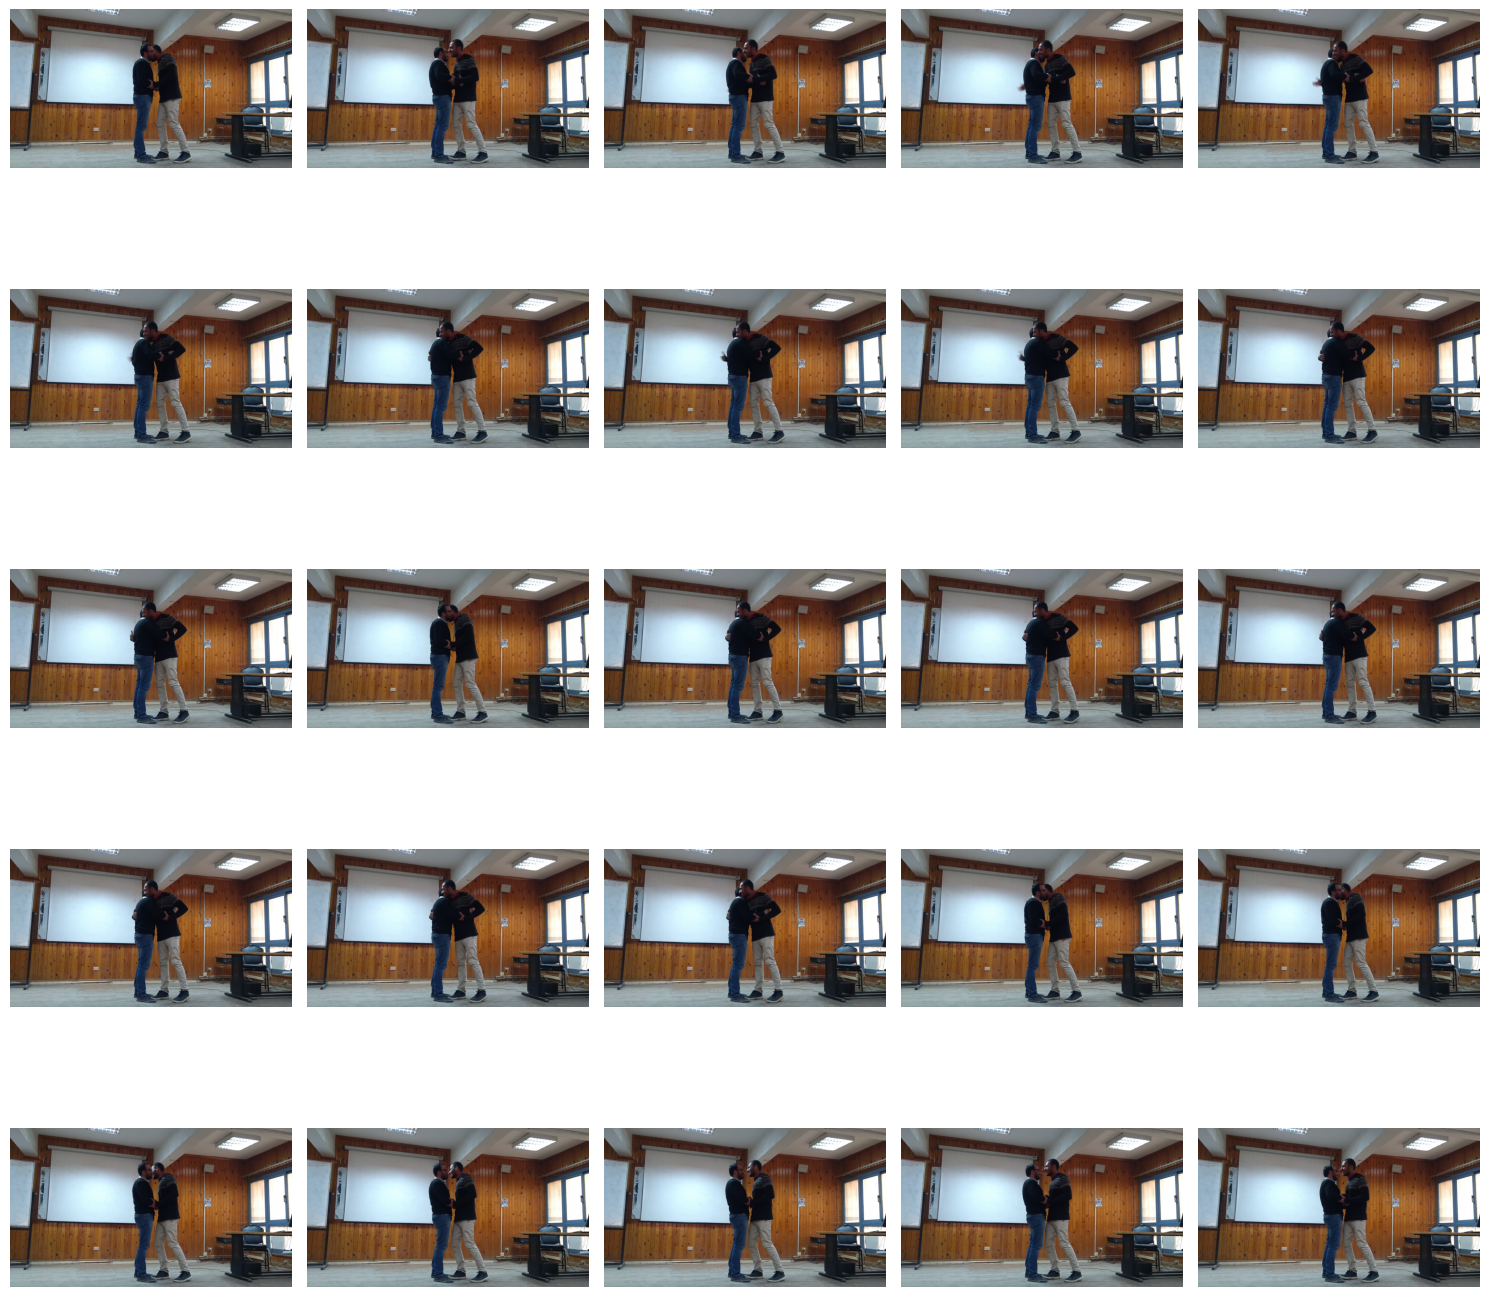

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os

video_name = "NV_1"
keyframes_dir = f"/content/content/uniform_samples/NonViolence/{video_name}"

keyframe_files = sorted([f for f in os.listdir(keyframes_dir) if f.startswith("keyframe_") and f.endswith(".jpg")])

fig, axes = plt.subplots(5, 5, figsize=(15, 15))
for i, keyframe_file in enumerate(keyframe_files):
    img_path = os.path.join(keyframes_dir, keyframe_file)
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    row = i // 5
    col = i % 5
    axes[row, col].imshow(img)
    axes[row, col].axis('off')

plt.tight_layout()
plt.show()

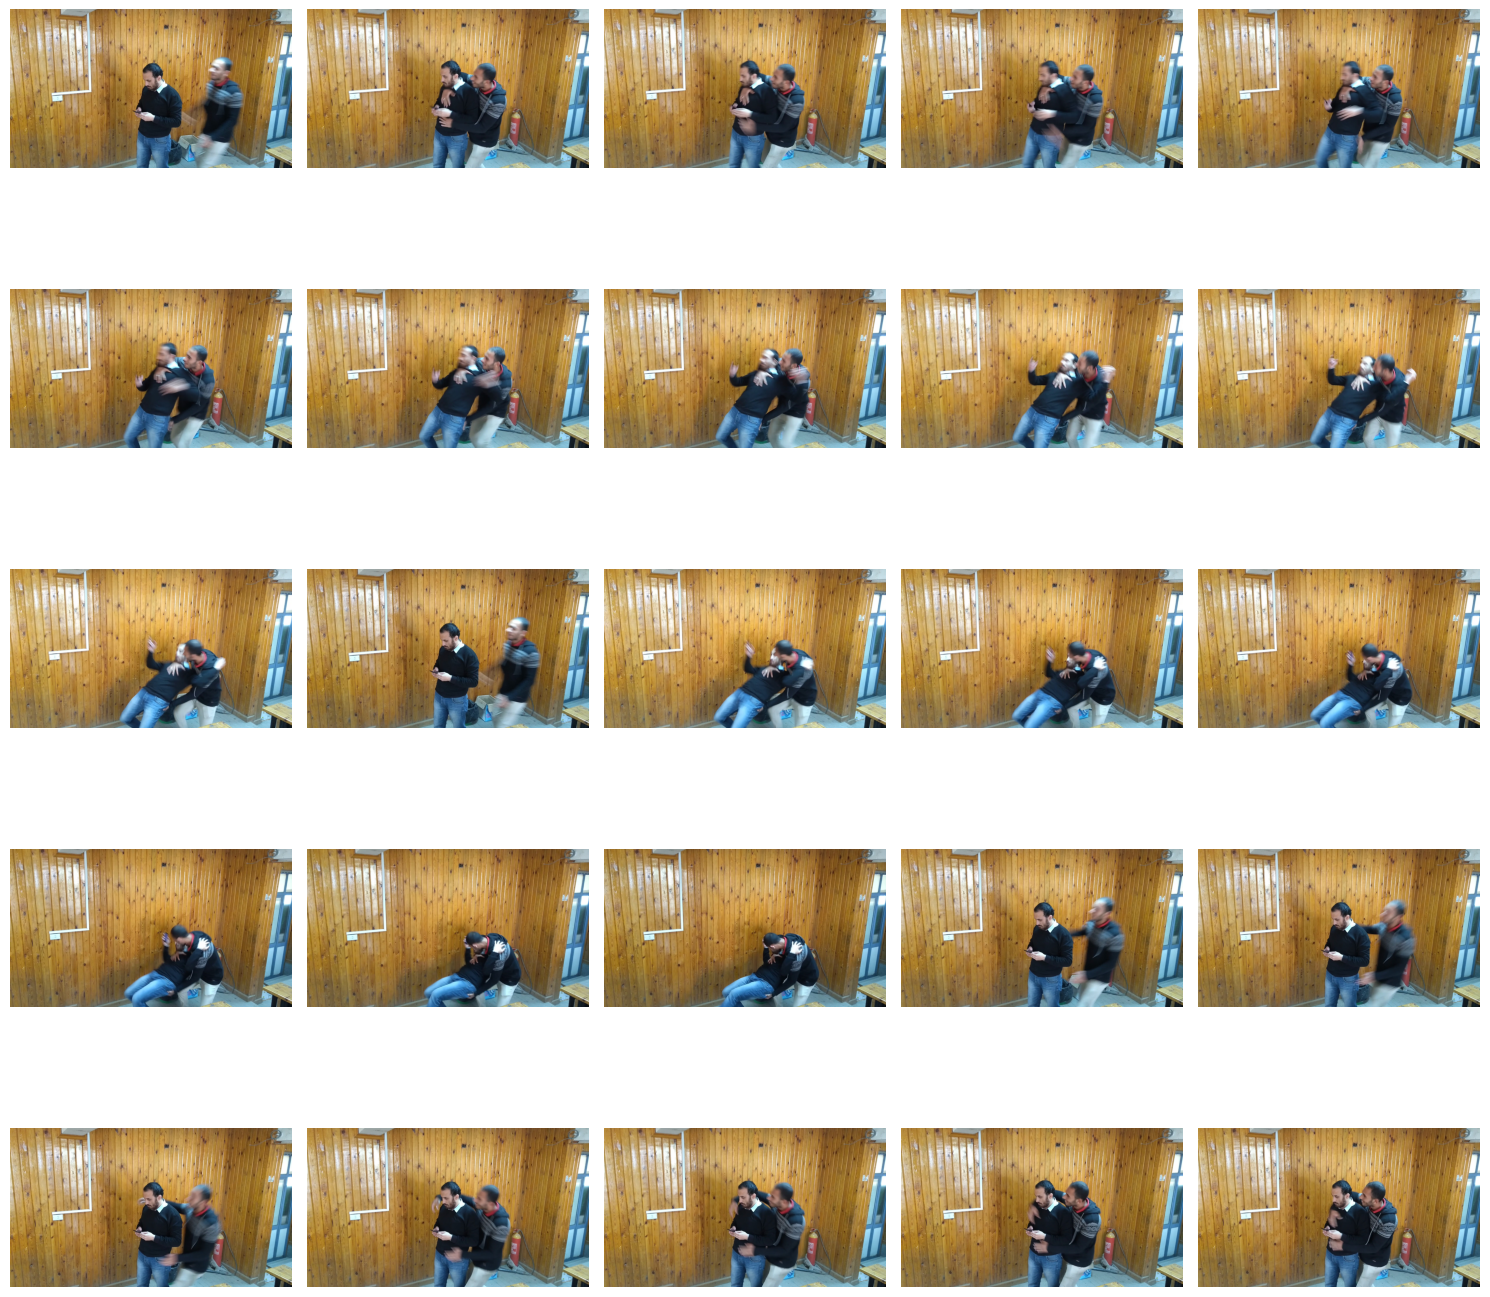

In [ ]:
 keyframes_dir = f"/content/content/uniform_samples/Violence/V_1"

keyframe_files = sorted([f for f in os.listdir(keyframes_dir) if f.startswith("keyframe_") and f.endswith(".jpg")])

fig, axes = plt.subplots(5, 5, figsize=(15, 15))
for i, keyframe_file in enumerate(keyframe_files):
    img_path = os.path.join(keyframes_dir, keyframe_file)
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    row = i // 5
    col = i % 5
    axes[row, col].imshow(img)
    axes[row, col].axis('off')

plt.tight_layout()
plt.show()